<a href="https://colab.research.google.com/github/sri-wahyuni10/Machine-learning-project/blob/main/TBC-basic/BasicdetectTBC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'D041181305_SRI WAHYUNI_PKMKC_PKM 2021_Pendanaan (1).pdf', 'D041181305_SRI WAHYUNI_PKMKC_PKM 2021_Pendanaan.pdf', 'Face recognition on Udemy.pdf', 'SRI WAHYUNI_2023_sertifikat_LIDM (1).pdf', 'SRI WAHYUNI_2023_sertifikat_LIDM.pdf', 'SRI WAHYUNI_2023_sertifikat_LIDM_001.png', 'Paper-Sri Wahyuni.pdf', 'Paper-Sri Wahyuni.docx', 'Sri Wahyuni - SmartHome', 'LPJ LIDM FIX.pdf', 'Komitmen dan Kontrak Belajar ADSE 2024 x DSI.pdf', 'Graduation Certificate English Version.pdf', 'Graduation Certificate Real.pdf', 'TRANSCRIPT OF ACADEMIC ACHIEVEMENT.pdf', 'TRANSCRIPT OF ACADEMIC.pdf', 'CV.pdf', 'AI Workflow Audit and Tool Setup.docx', 'Proof Statement.gdoc', 'Sri_Wahyuni_CV_ML_DataScience.pdf', 'malaria-cv', 'tbc-cv']


In [ ]:
import os, getpass
os.environ['KAGGLE_API_TOKEN'] = getpass.getpass('Tempel token: ')

Tempel token: ··········


In [ ]:
!pip install -q --upgrade kaggle
!kaggle datasets list -s "tuberculosis chest"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 3.2 MB/s eta 0:00:00
ref                                                            title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-------------------------------------------------------------  -------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
tawsifurrahman/tuberculosis-tb-chest-xray-dataset              Tuberculosis (TB) Chest X-ray Database               695602161  2021-06-14 09:58:38.207000          44113        334  0.9375           
jtiptj/chest-xray-pneumoniacovid19tuberculosis                 Chest X-Ray (Pneumonia,Covid-19,Tuberculosis)       1866887032  2021-09-16 06:21:54.430000          17502        124  0.8125           
iamtapendu/chest-x-ray-lungs-segmentation                      Chest X-ray Dataset for Tuberculosis Segmentation   385517157

In [ ]:
os.makedirs('/content/drive/MyDrive/tbc-cv', exist_ok=True)
!kaggle datasets download -d tawsifurrahman/tuberculosis-tb-chest-xray-dataset -p /content/drive/MyDrive/tbc-cv

Dataset URL: https://www.kaggle.com/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset
License(s): copyright-authors
tuberculosis-tb-chest-xray-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!unzip -q /content/drive/MyDrive/tbc-cv/tuberculosis-tb-chest-xray-dataset.zip -d /content/data
print(os.listdir('/content/data'))

['TB_Chest_Radiography_Database']


In [ ]:
data_dir = '/content/data/TB_Chest_Radiography_Database'
print(os.listdir(data_dir))

['Tuberculosis.metadata.xlsx', 'README.md.txt', 'Normal', 'Tuberculosis', 'Normal.metadata.xlsx']


In [ ]:
for kelas in ['Normal', 'Tuberculosis']:
  print(kelas, len(os.listdir(data_dir + '/' + kelas)))

Normal 3500
Tuberculosis 700


In [ ]:
open(data_dir + '/README.md.txt').read()

'\ufeff*****Tuberculosis(TB) CHEST X-RAY DATABASE\n\nA team of researchers from Qatar University, Doha, Qatar, and the University of Dhaka, Bangladesh along with their collaborators from Malaysia in collaboration with medical doctors from Hamad Medical Corporation and Bangladesh have created a database of chest X-ray images for Tuberculosis (TB) positive cases along with Normal images. In our current release, there are 3500 TB images, and 3500 normal images.\n\n**Tuberculosis(TB) data:\n-----------------------\n700 TB data are collected from different publicly accessible dataset. 2800 TB data are collected from NIAID TB portal program dataset by signing an agreement.\n-306 CXR images from BELARUS TB portal program dataset[2].\n-394 CXR image from NLM [1]\n-2800 CXR images are collected from NIAID TB portal program dataset[3]. \n\nNote: Due to the data-sharing restriction, we have to direct the potential user to NIAID website where you can get data-sharing agreement signing \noption and

Text(0.5, 1.0, 'Tuberculosis')

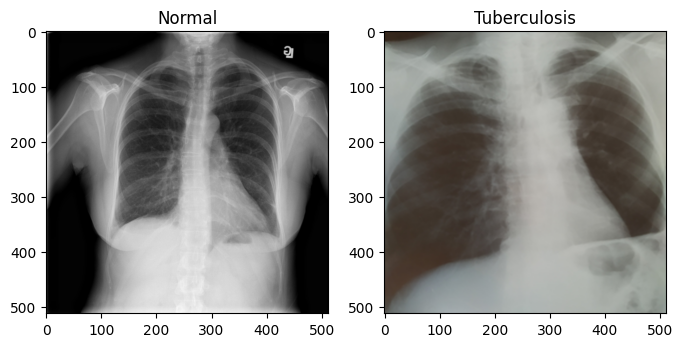

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

nama_tb = os.listdir(data_dir + '/Tuberculosis')[0]
nama_normal = os.listdir(data_dir + '/Normal')[0]

gambar_tb =Image.open(data_dir + '/Tuberculosis/' + nama_tb)
gambar_normal = Image.open(data_dir + '/Normal/' + nama_normal)

fig, ax = plt.subplots(1,2, figsize=(8,4))
ax[0].imshow(gambar_normal, cmap='gray')
ax[0].set_title('Normal')
ax[1].imshow(gambar_tb, cmap='gray')
ax[1].set_title('Tuberculosis')

In [ ]:
import numpy as np

a = np.array(gambar_tb) #mengubah gambar jadi tabel angka
print(a.shape, a.min(), a.max())
print(a[:5, :5])

(512, 512, 3) 26 194
[[[56 42 29]
  [56 42 29]
  [55 41 29]
  [54 40 29]
  [54 40 30]]

 [[56 42 29]
  [56 42 29]
  [55 41 29]
  [54 40 29]
  [54 40 30]]

 [[55 41 28]
  [55 41 28]
  [54 40 29]
  [54 40 29]
  [54 40 29]]

 [[55 41 28]
  [55 41 28]
  [54 40 29]
  [54 40 29]
  [54 40 29]]

 [[55 41 28]
  [55 41 28]
  [54 40 28]
  [54 40 28]
  [54 40 29]]]


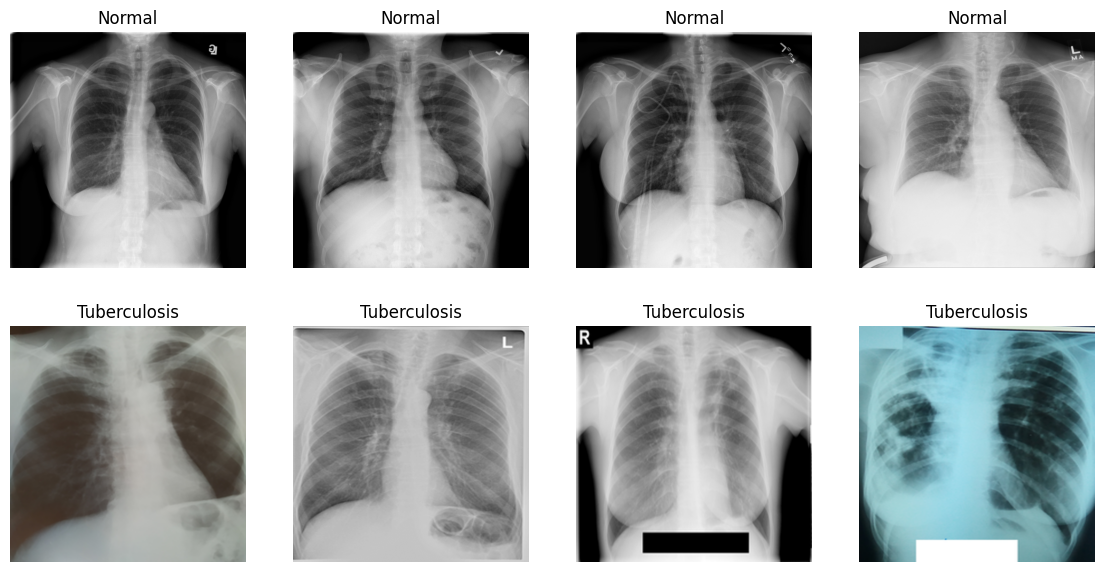

In [ ]:
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for i, kelas in enumerate(['Normal', 'Tuberculosis']):
    nama_file = os.listdir(data_dir + '/' + kelas)[:4]
    for j, nama in enumerate(nama_file):
        g = Image.open(data_dir + '/' + kelas + '/' + nama)
        ax[i, j].imshow(g, cmap='gray')
        ax[i, j].set_title(kelas)
        ax[i, j].axis('off')
plt.show()

In [ ]:
from collections import Counter

for kelas in ['Normal', 'Tuberculosis']:
    daftar = os.listdir(data_dir + '/' + kelas)
    hitung = Counter(Image.open(data_dir + '/' + kelas + '/' + n).mode for n in daftar)
    print(kelas, hitung)

Normal Counter({'RGB': 3500})
Tuberculosis Counter({'RGB': 392, 'L': 308})


In [ ]:
#seberapa banyak gambar yang benar-benar berwarna?
import random

def selisih_warna(kelas, n=200):
    daftar = random.sample(os.listdir(data_dir + '/' + kelas), n)
    hasil = []
    for nama in daftar:
        a = np.array(Image.open(data_dir + '/' + kelas + '/' + nama).convert('RGB')).astype(int)
        hasil.append(np.abs(a[:, :, 0] - a[:, :, 2]).mean())
    return np.array(hasil)

for kelas in ['Normal', 'Tuberculosis']:
    s = selisih_warna(kelas)
    print(kelas, 'rata-rata selisih:', s.mean().round(2), '| berwarna (>5):', (s > 5).sum(), 'dari', len(s))

Normal rata-rata selisih: 0.0 | berwarna (>5): 0 dari 200
Tuberculosis rata-rata selisih: 17.34 | berwarna (>5): 106 dari 200


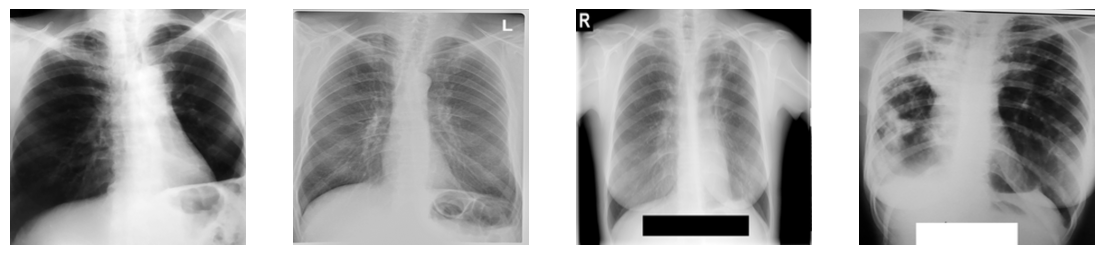

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(14, 4))
nama_file = os.listdir(data_dir + '/Tuberculosis')[:4]
for j, nama in enumerate(nama_file):
    g = Image.open(data_dir + '/Tuberculosis/' + nama).convert('L')
    ax[j].imshow(g, cmap='gray')
    ax[j].axis('off')
plt.show()

In [ ]:
import pandas as pd
meta_tb = pd.read_excel(data_dir + '/Tuberculosis.metadata.xlsx')
meta_normal = pd.read_excel(data_dir + '/Normal.metadata.xlsx')
print(meta_tb.columns.tolist())
print(meta_tb.head())
print(meta_tb.shape, meta_normal.shape)

['FILE NAME', 'FORMAT', 'SIZE', 'URL']
        FILE NAME FORMAT     SIZE                      URL
0  Tuberculosis-1    PNG  512*512  http://tuberculosis.by/
1  Tuberculosis-2    PNG  512*512  http://tuberculosis.by/
2  Tuberculosis-3    PNG  512*512  http://tuberculosis.by/
3  Tuberculosis-4    PNG  512*512  http://tuberculosis.by/
4  Tuberculosis-5    PNG  512*512  http://tuberculosis.by/
(700, 4) (3500, 4)


In [ ]:
print(meta_tb['URL'].value_counts())
print(meta_normal['URL'].value_counts())

URL
https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4256233/    394
http://tuberculosis.by/                                  306
Name: count, dtype: int64
URL
https://www.kaggle.com/c/rsna-pneumonia-detection-challenge/data    3094
https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4256233/                406
Name: count, dtype: int64


In [ ]:
nlm = 'https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4256233/'

tb_nlm = meta_tb[meta_tb['URL'] == nlm]['FILE NAME']
normal_nlm = meta_normal[meta_normal['URL'] == nlm]['FILE NAME']

print(len(tb_nlm), len(normal_nlm))
print(tb_nlm.head(3).tolist())
print(os.listdir(data_dir + '/Tuberculosis')[:3])

394 406
['Tuberculosis-307', 'Tuberculosis-308', 'Tuberculosis-309']
['Tuberculosis-288.png', 'Tuberculosis-167.png', 'Tuberculosis-278.png']


In [ ]:
daftar = []
for n in tb_nlm:
  daftar.append((data_dir + 'Tuberculosis/' + n + '.png', 1))
for n in normal_nlm:
  daftar.append((data_dir + '/Normal/' + n + '.png', 0))

data_df = pd.DataFrame(daftar, columns=['path', 'label'])

print(data_df.shape)
print(data_df['label'].value_counts())
print(data_df['path'].apply(os.path.exists).all())


(800, 2)
label
0    406
1    394
Name: count, dtype: int64
False


In [ ]:
ada = data_df['path'].apply(os.path.exists)
print(ada.value_counts())
print(data_df[~ada].head(3))
print(normal_nlm.head(3).tolist())
print(os.listdir(data_dir + '/Normal')[:3])

path
True     406
False    394
Name: count, dtype: int64
                                                path  label
0  /content/data/TB_Chest_Radiography_DatabaseTub...      1
1  /content/data/TB_Chest_Radiography_DatabaseTub...      1
2  /content/data/TB_Chest_Radiography_DatabaseTub...      1
['Normal-1', 'Normal-2', 'Normal-3']
['Normal-3219.png', 'Normal-3135.png', 'Normal-2468.png']


In [ ]:
daftar = []
for n in tb_nlm:
    daftar.append((os.path.join(data_dir, 'Tuberculosis', n + '.png'), 1))
for n in normal_nlm:
    daftar.append((os.path.join(data_dir, 'Normal', n + '.png'), 0))

data_df = pd.DataFrame(daftar, columns=['path', 'label'])
print(data_df['path'].apply(os.path.exists).value_counts())

path
True    800
Name: count, dtype: int64


sekarang kita punya daftar yang bersih: 800 gambar dari satu sumber (NLM), dengan 406 Normal dan 394 TBC, hampir seimbang.

In [ ]:
from sklearn.model_selection import train_test_split

train_df, sisa = train_test_split(data_df, test_size=0.3, stratify=data_df['label'], random_state=42)
val_df, test_df = train_test_split(sisa, test_size=0.5, stratify=sisa['label'], random_state=42)

for nama, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
  print(nama, len(d), d['label'].value_counts().to_dict())

train 560 {0: 284, 1: 276}
val 120 {0: 61, 1: 59}
test 120 {0: 61, 1: 59}


train_test_split memecah tabel menjadi dua bagian secara acak. Di pemecahan pertama, 30% (test_size=0.3) menjadi sisa dan 70% menjadi train_df.
Pemecahan kedua membagi sisa menjadi dua bagian sama besar: val_df dan test_df. Jadi hasil akhirnya kira-kira 70% / 15% / 15%.
stratify=...label menjaga perbandingan TBC dan Normal tetap sama di tiap bagian. Tanpa itu, secara kebetulan satu bagian bisa berisi lebih banyak TBC dari yang lain.
random_state=42 mengunci acakannya, jadi pembagiannya sama setiap kali dijalankan. Angka 42 bebas dipilih, yang penting tetap sama.
Loop di bawahnya hanya mencetak ukuran dan jumlah tiap kelas di tiap bagian.

In [ ]:
#simpan pembagian model ke drive
save_dir = '/content/drive/MyDrive/tbc-cv'
train_df.to_csv(save_dir + '/train.csv', index=False)
val_df.to_csv(save_dir + '/val.csv', index=False)
test_df.to_csv(save_dir + '/test.csv', index=False)

In [ ]:
def muat_gambar(path, ukuran=224):
    g = Image.open(path).convert('L') #.convert('L') mengubah ke satu lapisan abu-abu
    g = g.resize((ukuran, ukuran))
    return np.array(g) / 255.0

a = muat_gambar(train_df['path'].iloc[0])
print(a.shape, a.min(), a.max())

(224, 224) 0.0 0.9882352941176471


In [ ]:
def muat_semua(tabel):
    X = np.array([muat_gambar(p) for p in tabel['path']], dtype='float32')
    y = tabel['label'].values
    return X, y

X_train, y_train = muat_semua(train_df)
X_val, y_val = muat_semua(val_df)
X_test, y_test = muat_semua(test_df)
print(X_train.shape, X_val.shape, X_test.shape)

(560, 224, 224) (120, 224, 224) (120, 224, 224)


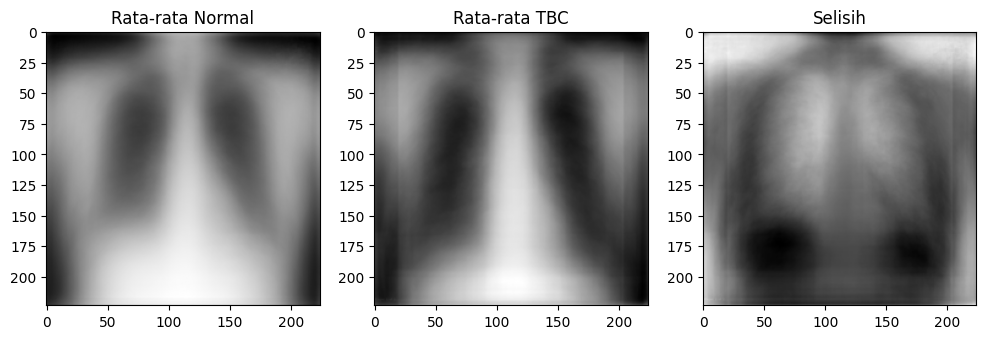

In [ ]:
#lihat “gambar rata-rata” tiap kelas
rata_normal = X_train[y_train == 0].mean(axis=0)
rata_tb = X_train[y_train == 1].mean(axis=0)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(rata_normal, cmap='gray'); ax[0].set_title('Rata-rata Normal')
ax[1].imshow(rata_tb, cmap='gray'); ax[1].set_title('Rata-rata TBC')
ax[2].imshow(rata_tb - rata_normal, cmap='gray'); ax[2].set_title('Selisih')
plt.show()

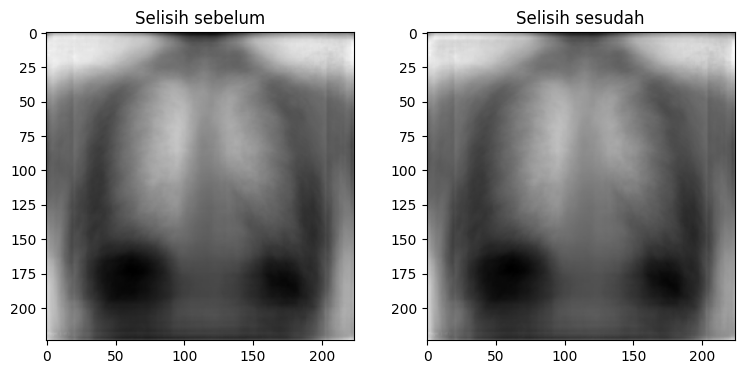

In [ ]:
#seragamkan kecerahan tiap gambar, lalu periksa lagi.
def standarkan(X):
    rata = X.mean(axis=(1, 2), keepdims=True)
    sd = X.std(axis=(1, 2), keepdims=True)
    return (X - rata) / (sd + 1e-6)

Xs_train = standarkan(X_train)
selisih_lama = X_train[y_train == 1].mean(axis=0) - X_train[y_train == 0].mean(axis=0)
selisih_baru = Xs_train[y_train == 1].mean(axis=0) - Xs_train[y_train == 0].mean(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(selisih_lama, cmap='gray'); ax[0].set_title('Selisih sebelum')
ax[1].imshow(selisih_baru, cmap='gray'); ax[1].set_title('Selisih sesudah')
plt.show()

In [ ]:
#BASELINE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score

Xs_val = standarkan(X_val)

def fitur_garis(X, n=4):
    bagian = np.array_split(X, n, axis=1)
    return np.stack([b.mean(axis=(1, 2)) for b in bagian], axis=1)

F_train = fitur_garis(Xs_train)
F_val = fitur_garis(Xs_val)

model = LogisticRegression().fit(F_train, y_train)
tebak = model.predict(F_val)
print('accuracy:', accuracy_score(y_val, tebak))
print('recall:', recall_score(y_val, tebak))

accuracy: 0.7416666666666667
recall: 0.6949152542372882


Tanda penyakit yang nyata: TBC bisa membuat bagian atas paru lebih berkabut, dan itu mengubah terang pita atas.

Jalan pintas dari gambar: perbedaan bingkai, potongan, atau terang latar antara foto TBC dan Normal

beri model hanya bagian tepi gambar, yang sebagian besar tidak berisi paru. Kalau dari tepi saja model sudah bisa menebak jauh di atas 51%, berarti ada informasi non-medis yang bocor.

In [ ]:
def fitur_tepi(X, t=20):
    atas = X[:, :t, :].mean(axis=(1, 2))
    bawah = X[:, -t:, :].mean(axis=(1, 2))
    kiri = X[:, :, :t].mean(axis=(1, 2))
    kanan = X[:, :, -t:].mean(axis=(1, 2))
    return np.stack([atas, bawah, kiri, kanan], axis=1)

E_train = fitur_tepi(X_train)
E_val = fitur_tepi(X_val)

model_tepi = LogisticRegression().fit(E_train, y_train)
tebak_tepi = model_tepi.predict(E_val)
print('accuracy:', accuracy_score(y_val, tebak_tepi))
print('recall:', recall_score(y_val, tebak_tepi))

accuracy: 0.6416666666666667
recall: 0.559322033898305


Dari tepi gambar saja, accuracy-nya 64%, jauh di atas patokan 51% (menebak “Normal” terus).
Dari empat pita horizontal seluruh gambar tadi, hasilnya 74%.
Tepi gambar sebagian besar bukan paru. Jadi sebagian besar kemampuan menebaknya (sekitar 13 dari 23 poin di atas kebetulan) bisa didapat tanpa melihat paru. Ini kira-kira, bukan angka pasti.

Artinya, ada informasi di tepi gambar yang bisa dipakai model sebagai jalan pintas, padahal informasi itu bukan tanda penyakit.

In [ ]:
#buang tepinya dengan memotong bagian tengah gambar saja, lalu cek apakah jalan pintasnya mengecil.
def muat_gambar_potong(path, ukuran=224, bagian=0.8):
    g = Image.open(path).convert('L')
    w, h = g.size
    pw, ph = int(w * (1 - bagian) / 2), int(h * (1 - bagian) / 2)
    g = g.crop((pw, ph, w - pw, h - ph))
    g = g.resize((ukuran, ukuran))
    return np.array(g) / 255.0

X_train2 = np.array([muat_gambar_potong(p) for p in train_df['path']], dtype='float32')
X_val2 = np.array([muat_gambar_potong(p) for p in val_df['path']], dtype='float32')

model_tepi2 = LogisticRegression().fit(fitur_tepi(X_train2), y_train)
tebak2 = model_tepi2.predict(fitur_tepi(X_val2))
print('accuracy:', accuracy_score(y_val, tebak2))
print('recall:', recall_score(y_val, tebak2))

accuracy: 0.7666666666666667
recall: 0.7627118644067796


Sekarang CNN-nya. Kita susun dulu modelnya dan baca strukturnya sebelum melatih apa pun. CNN pertama ini memakai gambar penuh sebagai patokan. Potongan tengah kita coba sebagai percobaan terpisah nanti, supaya hasilnya bisa dibandingkan.

In [ ]:
!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

Xtr = X_train[..., np.newaxis]
Xva = X_val[..., np.newaxis]
print(Xtr.shape)

model = models.Sequential([
    layers.Input(shape=(224, 224, 1)),
    layers.Conv2D(8,3, activation = 'relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(16, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(1, activation='sigmoid'),
])

model.summary()

(560, 224, 224, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 8)    │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 8)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 16)   │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,921 (23.13 KB)

 Trainable params: 5,921 (23.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#mulai melatih model
tf.random.set_seed(42)

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics =['accuracy', tf.keras.metrics.Recall(name='recall'), tf.keras.metrics.AUC(name='auc')]
)

riwayat = model.fit(
    Xtr, y_train,
    validation_data = (Xva, y_val),
    epochs=15,
    batch_size=32
)

Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 13s 507ms/step - accuracy: 0.5036 - auc: 0.4829 - loss: 0.6949 - recall: 0.9275 - val_accuracy: 0.5083 - val_auc: 0.4912 - val_loss: 0.6921 - val_recall: 0.0000e+00
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 499ms/step - accuracy: 0.5071 - auc: 0.6128 - loss: 0.6911 - recall: 0.0000e+00 - val_accuracy: 0.5083 - val_auc: 0.7469 - val_loss: 0.6891 - val_recall: 0.0000e+00
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 483ms/step - accuracy: 0.5089 - auc: 0.6465 - loss: 0.6899 - recall: 0.0036 - val_accuracy: 0.5083 - val_auc: 0.7809 - val_loss: 0.6842 - val_recall: 0.0000e+00
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 12s 565ms/step - accuracy: 0.5536 - auc: 0.6260 - loss: 0.6869 - recall: 0.1775 - val_accuracy: 0.5167 - val_auc: 0.7659 - val_loss: 0.6777 - val_recall: 0.0169
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 468ms/step - accuracy: 0.5911 - auc: 0.6272 - loss: 0.6829 - recall: 0.3043 - val_accuracy: 0.6750 - val_auc: 0.7604 - val_loss: 0.6671 - val_recall

In [ ]:
#lanjutkan training lebih lama
simpan = tf.keras.callbacks.ModelCheckpoint(
    save_dir + '/cnn_tbc_terbaik.keras',
    monitor='val_loss',
    save_best_only=True
)

riwayat2 = model.fit(
    Xtr, y_train,
    validation_data=(Xva, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[simpan]
)

pd.DataFrame(riwayat2.history).to_csv(save_dir + '/cnn_tbc_history.csv', index=False)

Epoch 1/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 489ms/step - accuracy: 0.6393 - auc: 0.7053 - loss: 0.6287 - recall: 0.6014 - val_accuracy: 0.7250 - val_auc: 0.8165 - val_loss: 0.5761 - val_recall: 0.7288
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 483ms/step - accuracy: 0.6464 - auc: 0.7118 - loss: 0.6238 - recall: 0.5942 - val_accuracy: 0.7583 - val_auc: 0.8231 - val_loss: 0.5702 - val_recall: 0.7288
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 512ms/step - accuracy: 0.6464 - auc: 0.7192 - loss: 0.6192 - recall: 0.6051 - val_accuracy: 0.6917 - val_auc: 0.8220 - val_loss: 0.5711 - val_recall: 0.7797
Epoch 4/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 449ms/step - accuracy: 0.6482 - auc: 0.7299 - loss: 0.6121 - recall: 0.5797 - val_accuracy: 0.7417 - val_auc: 0.8265 - val_loss: 0.5616 - val_recall: 0.7797
Epoch 5/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 430ms/step - accuracy: 0.6554 - auc: 0.7342 - loss: 0.6084 - recall: 0.5978 - val_accuracy: 0.6833 - val_auc: 0.8283 - val_loss: 0.5625 - val_recall: 0.7797
Epoch 6/

In [ ]:
terbaik = tf.keras.models.load_model(save_dir + '/cnn_tbc_terbaik.keras')
prob = terbaik.predict(Xva).ravel()
tebak = (prob >= 0.5).astype(int)

from sklearn.metrics import confusion_matrix
tn, fp, fn, tp = confusion_matrix(y_val, tebak).ravel()
print('TN', tn, 'FP', fp, 'FN', fn, 'TP', tp)
print('recall', round(tp / (tp + fn), 3), '| spec', round(tn / (tn + fp), 3))

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 267ms/step
TN 47 FP 14 FN 8 TP 51
recall 0.864 | spec 0.77


confusion_matrix menghitung empat kemungkinan:
TP: TBC yang ditemukan.
FN: TBC yang lolos (dikira Normal).
FP: Normal yang salah dicurigai TBC.
TN: Normal yang dinilai benar.

Angkanya persis seperti hitungan dari tabel training tadi: TP 51, FN 8, FP 14, TN 47. Artinya model menemukan 51 dari 59 kasus TBC (8 lolos), dan 14 dari 61 gambar Normal salah dicurigai TBC. Spec 0,77 lebih rendah dari recall 0,864, jadi model cenderung lebih mudah curiga TBC daripada melewatkannya. Untuk skrining itu arah yang masuk akal, tapi 14 salah curiga dari 61 tidak kecil.

In [ ]:
#melihat bagian gambar mana yang dipakai model.
masuk = tf.keras.Input(shape=(224, 224, 1))
x = masuk
for lapisan in terbaik.layers:
    x = lapisan(x)
    if lapisan.name == 'conv2d_2':
        peta_conv = x
grad_model = tf.keras.Model(masuk, [peta_conv, x])

def grad_cam(gambar):
    x = tf.convert_to_tensor(gambar[np.newaxis, ..., np.newaxis], dtype=tf.float32)
    with tf.GradientTape() as tape:
        peta, keluaran = grad_model(x)
        skor = keluaran[:, 0]
    grad = tape.gradient(skor, peta)
    bobot = tf.reduce_mean(grad, axis=(1, 2))
    cam = tf.reduce_sum(peta * bobot[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam).numpy()
    cam = cam / (cam.max() + 1e-8)
    return cam, float(skor[0])

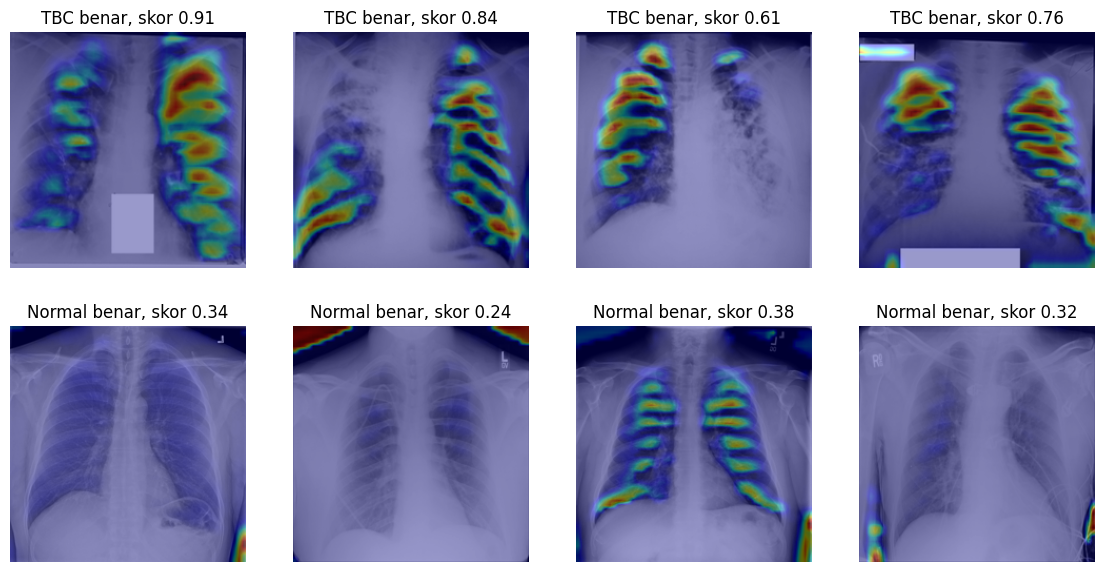

In [ ]:
idx_tp = np.where((y_val == 1) & (tebak == 1))[0][:4]
idx_tn = np.where((y_val == 0) & (tebak == 0))[0][:4]

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for baris, (idx_list, nama) in enumerate([(idx_tp, 'TBC benar'), (idx_tn, 'Normal benar')]):
    for k, i in enumerate(idx_list):
        cam, skor = grad_cam(X_val[i])
        cam_besar = np.array(Image.fromarray((cam * 255).astype('uint8')).resize((224, 224), Image.BILINEAR)) / 255.0
        ax[baris, k].imshow(X_val[i], cmap='gray')
        ax[baris, k].imshow(cam_besar, cmap='jet', alpha=0.4)
        ax[baris, k].set_title(nama + ', skor ' + str(round(skor, 2)))
        ax[baris, k].axis('off')
plt.show()

Baris TBC (skor 0,61 sampai 0,91):

Panas terkonsentrasi di dalam area paru, berbentuk pita-pita miring yang mengikuti arah tulang rusuk. Pada empat gambar itu, sudut dan tepi luar hampir tidak merah. Ini tanda baik: model tidak sekadar membaca sudut atau kotak di bawah. Dua gambar yang punya kotak di bawah (gambar pertama dan keempat) tidak memperlihatkan panas di kotaknya.
Tapi pita yang mengikuti tulang rusuk juga bisa berarti model bereaksi pada pola tulang rusuk dan tekstur paru secara umum, bukan pada lesi. Dari peta sekasar ini (26×26 yang dibesarkan), saya tidak bisa membedakannya. Apakah area merah itu memang tempat kelainan, hanya dokter yang bisa memastikan.
Skor 0,61 di gambar ketiga hanya sedikit di atas batas 0,5, jadi model sebenarnya ragu di situ.


Baris Normal (skor 0,24 sampai 0,38):

Gambar kedua punya bercak merah di pojok kiri atas, dan gambar pertama dan keempat tampak punya merah kecil di pojok bawah. Sekali lagi, panas di sini berarti “daerah ini mendorong skor ke arah TBC”, jadi pojok-pojok itu sedikit mendorong model ke TBC meski tebakan akhirnya tetap benar.
Gambar ketiga punya pita panas di kedua paru walau skornya 0,38, yaitu masih di bawah 0,5.

Angka 0,5/50% itu tidak dipelajari model dan bukan dari datamu. Itu kesepakatan umum: karena keluaran Dense (sigmoid) berada di antara 0 dan 1, titik tengahnya 0,5 dipakai sebagai garis pemisah. Di atasnya dianggap TBC, di bawahnya Normal. Saya yang menuliskannya di kode sebagai pilihan awal.

In [ ]:
def bagian_tepi(cam, lebar=0.1):
    besar = np.array(Image.fromarray((cam * 255).astype('uint8')).resize((224, 224), Image.BILINEAR)) / 255.0
    if besar.sum() == 0:
        return np.nan
    t = int(224 * lebar)
    tengah = besar[t:-t, t:-t].sum()
    return 1 - tengah / besar.sum()

hasil = []
for i in range(len(X_val)):
    cam, skor = grad_cam(X_val[i])
    hasil.append((y_val[i], bagian_tepi(cam)))
hasil = np.array(hasil, dtype=float)

for label in [0, 1]:
    pilih = hasil[hasil[:, 0] == label, 1]
    print('label', label, 'bagian panas di tepi:', np.nanmean(pilih).round(2))
print('luas tepi (patokan):', round(1 - (1 - 2 * 0.1) ** 2, 2))

label 0 bagian panas di tepi: 0.49
label 1 bagian panas di tepi: 0.34
luas tepi (patokan): 0.36


TBC (0,34): hampir sama dengan patokan, jadi panasnya tidak menumpuk di tepi. Tapi juga tidak sepenuhnya di tengah. Kemungkinan penyebabnya, gambar TBC dipotong lebih ketat, sehingga paru bagian samping memang berada dekat bingkai.
Normal (0,49): setengah panasnya jatuh di bingkai, padahal bingkai hanya 36% dari luas gambar. Itu cocok dengan bercak merah di pojok yang kita lihat di baris Normal tadi. Cara membacanya: pada gambar Normal, sinyal yang mendorong ke arah TBC sedikit dan lemah, dan sebagian besar yang tersisa ada di tepi.

In [ ]:
def tutup_tepi(X, lebar=0.1):
    Xc = X.copy()
    rata = X.mean(axis=(1, 2), keepdims=True)
    t = int(224 * lebar)
    Xc[:, :t, :] = rata
    Xc[:, -t:, :] = rata
    Xc[:, :, :t] = rata
    Xc[:, :, -t:] = rata
    return Xc

Xva2 = tutup_tepi(X_val)
prob2 = terbaik.predict(Xva2[..., np.newaxis]).ravel()
t2 = (prob2 >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val, t2).ravel()
print('accuracy', round((tn + tp) / len(y_val), 3), '| recall', round(tp / (tp + fn), 3), '| spec', round(tn / (tn + fp), 3))

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 175ms/step
accuracy 0.617 | recall 0.949 | spec 0.295


Yang terjadi: setelah tepinya ditutup, model menilai 99 dari 120 gambar sebagai TBC (56 TBC benar ditambah 43 Normal yang salah dicurigai). Recall naik bukan karena model jadi lebih pintar, tapi karena ia hampir menjawab “TBC” untuk semuanya. Spec jatuh dari 0,77 ke 0,30. Selisih sebesar itu jauh di atas derau dari 120 gambar (sekitar ±8 poin), jadi kemungkinan besar bukan kebetulan.

Artinya: model memang memakai informasi di tepi gambar. Kuat dugaan saya, sinyal di tepi itu membantu model memutuskan “Normal”. Saat tepinya diganti abu-abu, bukti untuk Normal hilang dan model condong ke TBC. Ini cocok dengan temuan kita sebelumnya: gambar Normal punya latar yang lebih gelap dan pola tepi tertentu, dan itu bukan tanda penyakit.

In [ ]:
def tutup_tepi(X, isi, lebar=0.1):
    Xc = X.copy()
    t = int(224 * lebar)
    Xc[:, :t, :] = isi
    Xc[:, -t:, :] = isi
    Xc[:, :, :t] = isi
    Xc[:, :, -t:] = isi
    return Xc

def ukur(Xin):
    p = terbaik.predict(Xin[..., np.newaxis], verbose=0).ravel()
    tn, fp, fn, tp = confusion_matrix(y_val, (p >= 0.5).astype(int)).ravel()
    return round((tn + tp) / len(y_val), 3), round(tp / (tp + fn), 3), round(tn / (tn + fp), 3)

rata = X_val.mean(axis=(1, 2), keepdims=True)
for nama, isi in [('abu-abu rata-rata', rata), ('hitam', 0.0), ('putih', 1.0)]:
    print(nama, 'acc, recall, spec:', ukur(tutup_tepi(X_val, isi)))

abu-abu rata-rata acc, recall, spec: (np.float64(0.617), np.float64(0.949), np.float64(0.295))
hitam acc, recall, spec: (np.float64(0.55), np.float64(0.085), np.float64(1.0))
putih acc, recall, spec: (np.float64(0.717), np.float64(0.814), np.float64(0.623))


Yang bisa disimpulkan: hanya dengan mengganti warna bingkai 10% (yang sebagian besar bukan paru), model berpindah dari “hampir semua Normal” ke “hampir semua TBC”. Model yang benar-benar menilai paru tidak seharusnya sepeka itu terhadap warna bingkai. Kuat dugaan saya, kecerahan di tepi ikut menentukan jawaban model. Polanya juga cocok dengan temuan sebelumnya: latar gelap di tepi bersamaan dengan “Normal” (gambar Normal rata-rata punya sudut gelap).

In [ ]:
#latih ulang model yang sama pada gambar yang tepinya sudah dipotong 20%
def buat_model():
    return models.Sequential([
        layers.Input(shape=(224, 224, 1)),
        layers.Conv2D(8, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(16, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dense(1, activation='sigmoid'),
    ])

tf.random.set_seed(42)
model2 = buat_model()
model2.compile(optimizer='adam', loss='binary_crossentropy',
               metrics=['accuracy', tf.keras.metrics.Recall(name='recall'), tf.keras.metrics.AUC(name='auc')])

simpan2 = tf.keras.callbacks.ModelCheckpoint(save_dir + '/cnn_tbc_potong.keras', monitor='val_loss', save_best_only=True)

model2.fit(X_train2[..., np.newaxis], y_train,
           validation_data=(X_val2[..., np.newaxis], y_val),
           epochs=45, batch_size=32, callbacks=[simpan2])

Epoch 1/45
18/18 ━━━━━━━━━━━━━━━━━━━━ 12s 548ms/step - accuracy: 0.5036 - auc: 0.5245 - loss: 0.6928 - recall: 0.5181 - val_accuracy: 0.5083 - val_auc: 0.7847 - val_loss: 0.6887 - val_recall: 0.0000e+00
Epoch 2/45
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 500ms/step - accuracy: 0.5071 - auc: 0.5707 - loss: 0.6926 - recall: 0.0000e+00 - val_accuracy: 0.5083 - val_auc: 0.7894 - val_loss: 0.6858 - val_recall: 0.0000e+00
Epoch 3/45
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 519ms/step - accuracy: 0.5089 - auc: 0.6717 - loss: 0.6881 - recall: 0.0036 - val_accuracy: 0.5167 - val_auc: 0.7702 - val_loss: 0.6812 - val_recall: 0.0169
Epoch 4/45
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 435ms/step - accuracy: 0.5286 - auc: 0.6570 - loss: 0.6850 - recall: 0.0543 - val_accuracy: 0.5417 - val_auc: 0.7819 - val_loss: 0.6741 - val_recall: 0.0678
Epoch 5/45
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 434ms/step - accuracy: 0.5821 - auc: 0.6543 - loss: 0.6794 - recall: 0.2319 - val_accuracy: 0.7083 - val_auc: 0.7815 - val_loss: 0.6586 - val_recall: 0.4

Accuracy dan loss hampir sama. Dengan 120 gambar val, selisih sekecil itu tidak berarti.
Recall lebih rendah di model baru (0,71 vs 0,86), dan AUC juga lebih rendah. Tapi val punya hanya 59 kasus TBC, jadi selisih itu masih bisa derau. Saya tidak bisa menyimpulkan model baru lebih buruk.
Model baru belum selesai belajar. val_loss masih turun di epoch-epoch terakhir, jadi 45 epoch kemungkinan belum cukup untuk dia.

In [ ]:
potong = tf.keras.models.load_model(save_dir + '/cnn_tbc_potong.keras')

def ukur_model(m, Xin):
    p = m.predict(Xin[..., np.newaxis], verbose=0).ravel()
    tn, fp, fn, tp = confusion_matrix(y_val, (p >= 0.5).astype(int)).ravel()
    return round(float((tn + tp) / len(y_val)), 3), round(float(tp / (tp + fn)), 3), round(float(tn / (tn + fp)), 3)

rata2 = X_val2.mean(axis=(1, 2), keepdims=True)
print('tanpa penutup', ukur_model(potong, X_val2))
for nama, isi in [('abu-abu rata-rata', rata2), ('hitam', 0.0), ('putih', 1.0)]:
    print(nama, ukur_model(potong, tutup_tepi(X_val2, isi)))

tanpa penutup (0.825, 0.712, 0.934)
abu-abu rata-rata (0.817, 0.661, 0.967)
hitam (0.492, 1.0, 0.0)
putih (0.775, 0.542, 1.0)


In [ ]:
np.savez_compressed(
    save_dir + '/data_tbc.npz',
    X_train=(X_train * 255).round().astype('uint8'),
    X_val=(X_val * 255).round().astype('uint8'),
    X_test=(X_test * 255).round().astype('uint8'),
    X_train2=(X_train2 * 255).round().astype('uint8'),
    X_val2=(X_val2 * 255).round().astype('uint8'),
    y_train=y_train, y_val=y_val, y_test=y_test
)
print(os.path.getsize(save_dir + '/data_tbc.npz') / 1e6, 'MB')

53.036164 MB


**Sesi setelah runtime**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix

save_dir = '/content/drive/MyDrive/tbc-cv'
d = np.load(save_dir + '/data_tbc.npz')
X_train = d['X_train'].astype('float32') / 255.0
X_val = d['X_val'].astype('float32') / 255.0
X_test = d['X_test'].astype('float32') / 255.0
X_train2 = d['X_train2'].astype('float32') / 255.0
X_val2 = d['X_val2'].astype('float32') / 255.0
y_train, y_val, y_test = d['y_train'], d['y_val'], d['y_test']
terbaik = tf.keras.models.load_model(save_dir + '/cnn_tbc_terbaik.keras')
potong = tf.keras.models.load_model(save_dir + '/cnn_tbc_potong.keras')
print(X_train.shape, X_val.shape, X_test.shape)

Mounted at /content/drive
(560, 224, 224) (120, 224, 224) (120, 224, 224)


In [2]:
def tutup_tepi(X, isi, lebar=0.1):
    Xc = X.copy()
    t = int(224 * lebar)
    Xc[:, :t, :] = isi
    Xc[:, -t:, :] = isi
    Xc[:, :, :t] = isi
    Xc[:, :, -t:] = isi
    return Xc

def ukur_model(m, Xin):
    p = m.predict(Xin[..., np.newaxis], verbose=0).ravel()
    tn, fp, fn, tp = confusion_matrix(y_val, (p >= 0.5).astype(int)).ravel()
    return round(float((tn + tp) / len(y_val)), 3), round(float(tp / (tp + fn)), 3), round(float(tn / (tn + fp)), 3)

rata2 = X_val2.mean(axis=(1, 2), keepdims=True)
print('tanpa penutup', ukur_model(potong, X_val2))
for nama, isi in [('abu-abu rata-rata', rata2), ('hitam', 0.0), ('putih', 1.0)]:
    print(nama, ukur_model(potong, tutup_tepi(X_val2, isi)))

tanpa penutup (0.825, 0.712, 0.934)
abu-abu rata-rata (0.817, 0.661, 0.967)
hitam (0.492, 1.0, 0.0)
putih (0.775, 0.542, 1.0)


Tes abu-abu, yang paling netral: model baru hampir tidak berubah (0,825 jadi 0,817), sedangkan model lama jatuh 20 poin (0,817 jadi 0,617). Selisih sebesar itu jauh di atas derau 120 gambar. Jadi memotong tepi membantu model tidak terlalu bergantung pada kecerahan tepi.
Tes hitam: model baru menjawab “TBC” untuk semua gambar (recall 1,0, spec 0,0), kebalikan dari model lama yang menjawab “Normal” untuk hampir semua. Arahnya berlawanan, jadi bukan pola sederhana “tepi gelap berarti Normal”. Model masih rapuh terhadap bingkai.
Satu catatan: bingkai hitam dan putih murni adalah tepi tajam yang tidak pernah ada di data latih, jadi model apa pun bisa “kaget” oleh itu. Karena itu tes abu-abu yang paling adil, dan tes hitam-putih sebaiknya dibaca sebagai uji ketahanan, bukan bukti pasti.

Kesimpulan jujurnya: pemotongan memperbaiki satu bentuk ketergantungan pada tepi, tapi belum membuat model kebal. Ini layak ditulis di laporan sebagai keterbatasan.

In [3]:
from sklearn.metrics import roc_auc_score

pA = terbaik.predict(X_val[..., np.newaxis], verbose=0).ravel()
pB = potong.predict(X_val2[..., np.newaxis], verbose=0).ravel()
print('AUC lama', round(roc_auc_score(y_val, pA), 3), '| AUC baru', round(roc_auc_score(y_val, pB), 3))

print('batas, recall lama, spec lama, recall baru, spec baru')
for batas in [0.3, 0.4, 0.5, 0.6, 0.7]:
    baris = [batas]
    for p in [pA, pB]:
        tn, fp, fn, tp = confusion_matrix(y_val, (p >= batas).astype(int)).ravel()
        baris += [round(float(tp / (tp + fn)), 2), round(float(tn / (tn + fp)), 2)]
    print(baris)

AUC lama 0.896 | AUC baru 0.865
batas, recall lama, spec lama, recall baru, spec baru
[0.3, 0.95, 0.33, 0.95, 0.31]
[0.4, 0.9, 0.54, 0.75, 0.82]
[0.5, 0.86, 0.77, 0.71, 0.93]
[0.6, 0.76, 0.87, 0.66, 1.0]
[0.7, 0.71, 0.95, 0.58, 1.0]


AUC lama 0,896 dan baru 0,865 hanya selisih 0,03. Dengan 120 gambar, itu masih dalam derau, jadi kemampuan membedakan kedua model kira-kira setara. Pada spec yang sama, model lama tampak sedikit lebih baik (sekitar 5 poin recall), tapi itu juga masih dalam derau.
Perbedaan utama terletak di posisi garis, bukan di kualitas. Model baru lebih “pelit” memberi skor tinggi, jadi di 0,5 ia melewatkan lebih banyak TBC. Menurunkan garisnya ke 0,3 menemukan hampir semua TBC (hanya 3 lolos), tapi 42 dari 61 orang sehat ikut dicurigai.
Dengan hanya 120 gambar, garis yang dipilih juga berderau. Jadi pilih angka bulat, jangan mengejar angka yang tampak paling bagus.

In [4]:
!unzip -q /content/drive/MyDrive/tbc-cv/tuberculosis-tb-chest-xray-dataset.zip -d /content/data

val_df = pd.read_csv(save_dir + '/val.csv')
test_df = pd.read_csv(save_dir + '/test.csv')
print(len(val_df), len(test_df), os.path.exists(test_df['path'].iloc[0]))

120 120 True


In [5]:
def muat_gambar_potong(path, ukuran=224, bagian=0.8):
    g = Image.open(path).convert('L')
    w, h = g.size
    pw, ph = int(w * (1 - bagian) / 2), int(h * (1 - bagian) / 2)
    g = g.crop((pw, ph, w - pw, h - ph))
    g = g.resize((ukuran, ukuran))
    return np.array(g) / 255.0

cek = np.array([muat_gambar_potong(p) for p in val_df['path'][:5]], dtype='float32')
print('selisih terbesar:', np.abs(cek - X_val2[:5]).max())

selisih terbesar: 0.0


selisih 0,0 berarti X_test2 dibuat dengan cara yang persis sama seperti data latih, jadi hasil test ini adil.

In [6]:
assert (y_test == test_df['label'].values).all()

X_test2 = np.array([muat_gambar_potong(p) for p in test_df['path']], dtype='float32')
p_test = potong.predict(X_test2[..., np.newaxis], verbose=0).ravel()
tebak_test = (p_test >= 0.4).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, tebak_test).ravel()
print('TN', tn, 'FP', fp, 'FN', fn, 'TP', tp)
print('recall', round(tp / (tp + fn), 3), '| spec', round(tn / (tn + fp), 3), '| accuracy', round((tn + tp) / len(y_test), 3))

from sklearn.metrics import roc_auc_score
print('AUC', round(roc_auc_score(y_test, p_test), 3))

TN 45 FP 16 FN 20 TP 39
recall 0.661 | spec 0.738 | accuracy 0.7
AUC 0.782


Turun dari val ke test itu wajar dan memang diharapkan. Kita memilih model, epoch, dan garis pemisah dengan melihat data val, jadi angka val sedikit terlalu optimis. Test adalah angka yang lebih jujur.
Ketidakpastiannya besar. Dengan 59 kasus TBC, recall 0,66 kira-kira berarti nilai sebenarnya antara 0,53 dan 0,77 (hitungan kasar saya). Spec kira-kira 0,62 sampai 0,83. Jadi kita tidak bisa bilang model “lebih buruk dari val”, hanya bahwa kemampuannya sedang dan belum cukup untuk dipakai sungguhan.
Ini hasil final. Sesuai aturan yang kita sepakati, angka ini tidak diubah, meski tidak sebagus yang diharapkan.

In [7]:
hasil = pd.DataFrame({'path': test_df['path'], 'label': y_test, 'skor': p_test, 'tebakan_0.4': tebak_test})
hasil.to_csv(save_dir + '/hasil_test_final.csv', index=False)

In [8]:
''' tabel sifat gambar untuk semua gambar test, dikelompokkan menurut jenis hasil (TP, TN, FP, FN)'''

def sifat_gambar(path):
    g = Image.open(path)
    abu = np.array(g.convert('L')) / 255.0
    a = np.array(g.convert('RGB')).astype(int)
    return g.mode, abu.mean(), abu.std(), np.abs(a[:, :, 0] - a[:, :, 2]).mean()

info = pd.DataFrame([sifat_gambar(p) for p in test_df['path']], columns=['mode', 'terang', 'kontras', 'warna'])
analisis = pd.concat([test_df.reset_index(drop=True), info], axis=1)
analisis['skor'] = p_test
analisis['jenis'] = np.select(
    [(y_test == 1) & (tebak_test == 0), (y_test == 0) & (tebak_test == 1), (y_test == 1)],
    ['FN', 'FP', 'TP'], default='TN')

print(analisis.groupby('jenis')[['skor', 'terang', 'kontras', 'warna']].mean().round(3))
print(pd.crosstab(analisis['jenis'], analisis['mode']))

        skor  terang  kontras   warna
jenis                                
FN     0.337   0.564    0.196  21.964
FP     0.570   0.433    0.267   0.000
TN     0.307   0.521    0.243   0.000
TP     0.762   0.428    0.240  24.338
mode   L  RGB
jenis        
FN     9   11
FP     0   16
TN     0   45
TP     8   31


Fungsinya: mengukur beberapa sifat sederhana tiap gambar test (jenis file, rata-rata terang, kontras, dan seberapa berwarna), menempelkannya ke hasil tebakan model, lalu merata-ratakan per kelompok. Kalau kelompok FN atau FP punya sifat yang jelas berbeda dari TP dan TN (misalnya jauh lebih gelap), itu petunjuk awal kelemahan model. Sifat diukur dari gambar asli penuh, bukan yang sudah dipotong. Karena tiap kelompok hanya 16 sampai 45 gambar, selisih kecil itu derau, jadi cari yang mencolok saja.

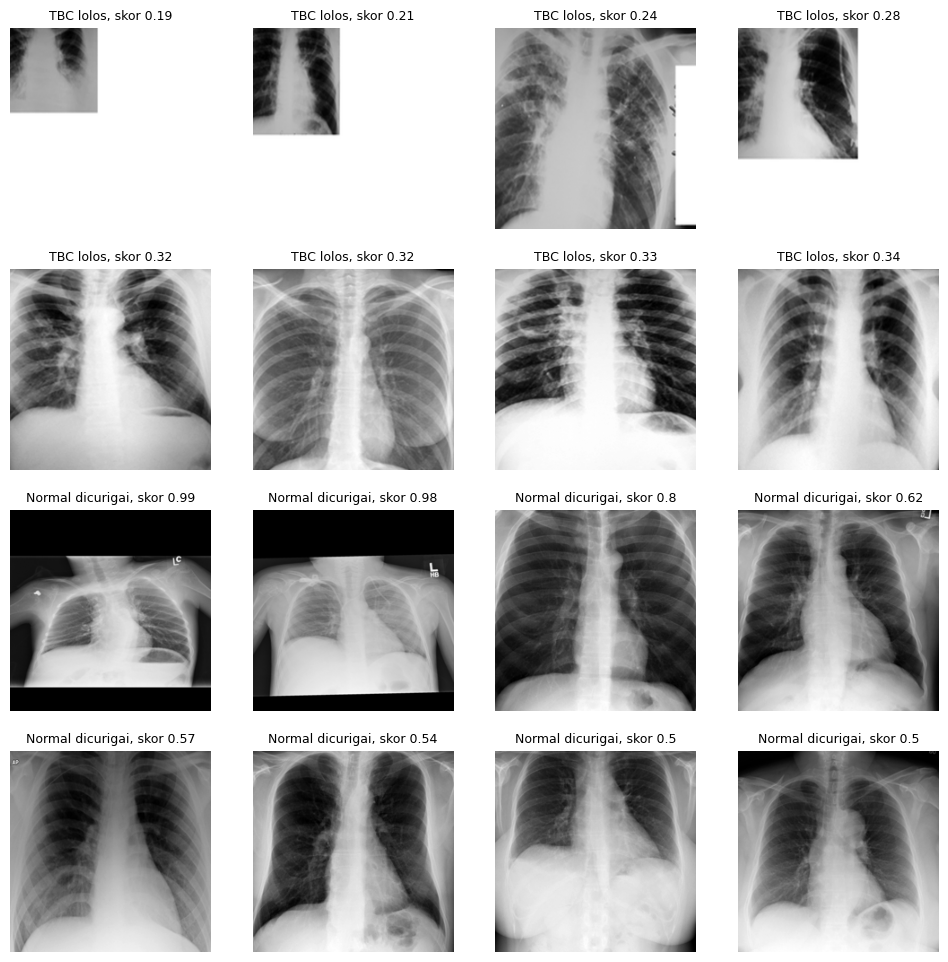

In [9]:
#lihat sendiri gambar yang paling salah

fn_idx = analisis[analisis['jenis'] == 'FN'].sort_values('skor').index[:8]
fp_idx = analisis[analisis['jenis'] == 'FP'].sort_values('skor', ascending=False).index[:8]

fig, ax = plt.subplots(4, 4, figsize=(12, 12))
for k, i in enumerate(list(fn_idx) + list(fp_idx)):
    a = ax[k // 4, k % 4]
    a.imshow(X_test2[i], cmap='gray')
    a.set_title(('TBC lolos' if k < 8 else 'Normal dicurigai') + ', skor ' + str(round(float(p_test[i]), 2)), fontsize=9)
    a.axis('off')
plt.show()

Fungsinya: menampilkan 8 gambar TBC yang paling yakin dinilai Normal (dua baris atas) dan 8 gambar Normal yang paling yakin dinilai TBC (dua baris bawah), diurutkan dari kesalahan terbesar. Yang ditampilkan adalah versi terpotong, persis seperti yang dilihat model.